# Delivery ETA: EDA, chronological modeling, and SHAP

This notebook analyzes a public delivery-operations dataset adapted to Saudi city names and zones. It is portfolio analysis, not real platform order data. The target is delivery time in minutes and the operational SLA assumption is 30 minutes.

In [1]:
from pathlib import Path
import csv
import gc
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix
from IPython.display import Markdown, display

from src.features import engineer_features
from src.train_model import train_models, SPLIT_DATE
from src.explainability import build_summary

ROOT = Path.cwd()
DATA = ROOT / 'data'
IMAGE_DIR = ROOT / 'docs' / 'images'
IMAGE_DIR.mkdir(parents=True, exist_ok=True)
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['figure.dpi'] = 100
pd.set_option('display.max_columns', 50)

def csv_shape(path):
    with path.open(encoding='utf-8-sig', newline='') as handle:
        reader = csv.reader(handle)
        header = next(reader)
        rows = sum(1 for _ in reader)
    return rows, len(header)

C:\Users\hp\Documents\Qoder\2026-11-26\341c5f21\delivery-eta-ops-copilot\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Data inventory and provenance

In [2]:
original_shape = csv_shape(DATA / 'raw' / 'Zomato Dataset.csv')
cleaned_shape = csv_shape(DATA / 'raw' / 'zomato_cleaned.csv')
orders = pd.read_csv(DATA / 'raw' / 'delivery_orders.csv')
features = engineer_features(orders)
inventory = pd.DataFrame({
    'artifact': ['Kaggle original', 'Cleaned mirror', 'Adapted orders', 'Engineered features'],
    'rows': [original_shape[0], cleaned_shape[0], len(orders), len(features)],
    'columns': [original_shape[1], cleaned_shape[1], orders.shape[1], features.shape[1]],
})
display(inventory)
gc.collect()
display(Markdown(
    f'**Date range:** {features.order_dt.min():%Y-%m-%d} to {features.order_dt.max():%Y-%m-%d}  \n'
    f'**Chronological split date:** {SPLIT_DATE:%Y-%m-%d}'
))

,artifact,rows,columns
0,Kaggle original,45584,20
1,Cleaned mirror,38964,22
2,Adapted orders,38964,27
3,Engineered features,38964,39


**Date range:** 2022-02-11 to 2022-04-06  
**Chronological split date:** 2022-03-22

The original file is retained verbatim. The cleaned mirror has 38,964 rows. Saudi cities, coordinates, and order categories in the adapted file are synthetic assumptions and must not be interpreted as real platform behavior.

## 2. Data quality

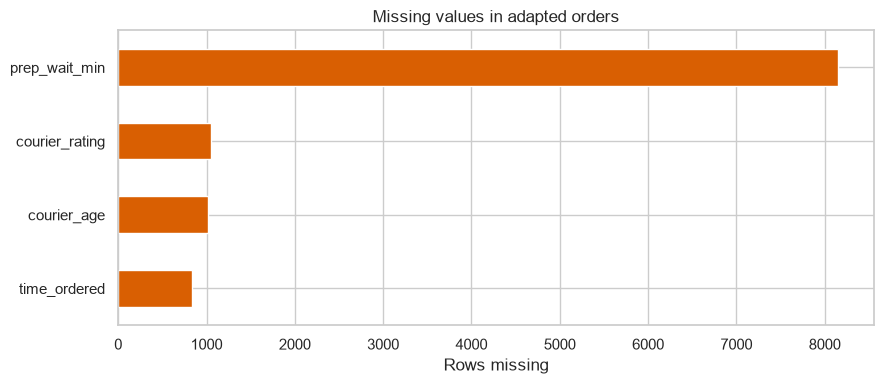

In [3]:
missing = orders.isna().sum()
missing = missing[missing > 0].sort_values(ascending=True)
fig, ax = plt.subplots(figsize=(9, 4))
missing.plot.barh(ax=ax, color='#d95f02')
ax.set_title('Missing values in adapted orders')
ax.set_xlabel('Rows missing')
fig.tight_layout()
fig.savefig(IMAGE_DIR / 'data_quality.png', dpi=120, bbox_inches='tight')
plt.show()
plt.close(fig)

## 3. Delivery-time and operations patterns

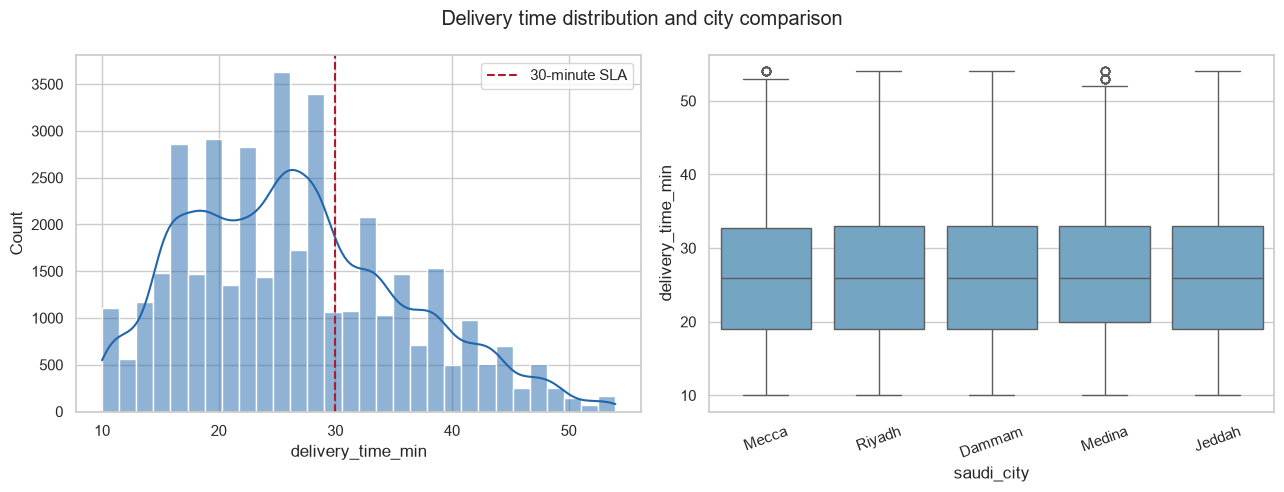

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.histplot(orders['delivery_time_min'], bins=30, kde=True, ax=axes[0], color='#2166ac')
axes[0].axvline(30, color='#b2182b', linestyle='--', label='30-minute SLA')
axes[0].legend()
sns.boxplot(data=orders, x='saudi_city', y='delivery_time_min', ax=axes[1], color='#67a9cf')
axes[1].tick_params(axis='x', rotation=20)
fig.suptitle('Delivery time distribution and city comparison')
fig.tight_layout()
fig.savefig(IMAGE_DIR / 'delivery_patterns.png', dpi=120, bbox_inches='tight')
plt.show()
plt.close(fig)

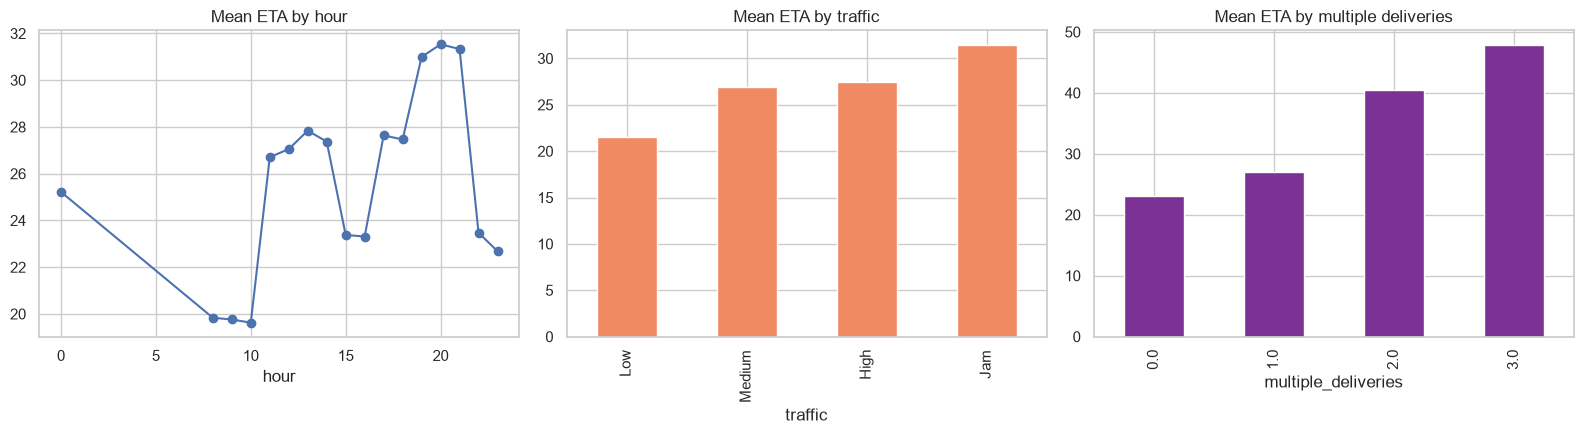

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
features.groupby('hour')['delivery_time_min'].mean().plot(ax=axes[0], marker='o')
axes[0].set_title('Mean ETA by hour')
orders.groupby('traffic')['delivery_time_min'].mean().sort_values().plot.bar(ax=axes[1], color='#ef8a62')
axes[1].set_title('Mean ETA by traffic')
orders.groupby('multiple_deliveries')['delivery_time_min'].mean().plot.bar(ax=axes[2], color='#7b3294')
axes[2].set_title('Mean ETA by multiple deliveries')
fig.tight_layout()
fig.savefig(IMAGE_DIR / 'operations_patterns.png', dpi=120, bbox_inches='tight')
plt.show()
plt.close(fig)

## 4. Chronological train/test split

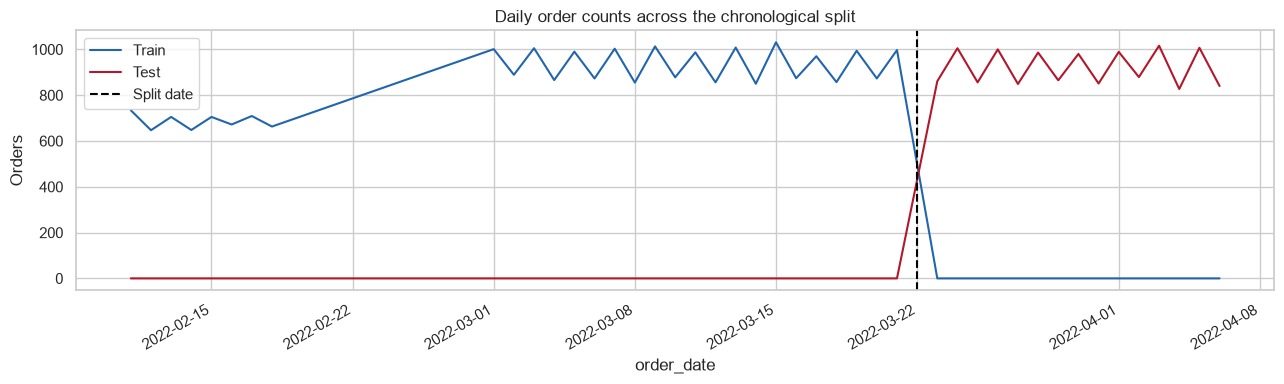

Train rows: 25153
Test rows: 13811


In [6]:
daily = features.groupby(['order_date', features['order_dt'] < SPLIT_DATE]).size().unstack(fill_value=0)
daily.columns = ['test', 'train']
fig, ax = plt.subplots(figsize=(13, 4))
daily['train'].plot(ax=ax, color='#2166ac', label='Train')
daily['test'].plot(ax=ax, color='#b2182b', label='Test')
ax.axvline(SPLIT_DATE, color='black', linestyle='--', label='Split date')
ax.set_title('Daily order counts across the chronological split')
ax.set_ylabel('Orders')
ax.legend()
fig.tight_layout()
fig.savefig(IMAGE_DIR / 'chronological_split.png', dpi=120, bbox_inches='tight')
plt.show()
plt.close(fig)
print('Train rows:', int((features.order_dt < SPLIT_DATE).sum()))
print('Test rows:', int((features.order_dt >= SPLIT_DATE).sum()))

## 5. Model fitting and comparison

In [7]:
del orders
gc.collect()
metrics, test_predictions = train_models(features, ROOT)
comparison = pd.DataFrame([metrics['baseline'], metrics['xgboost'], metrics['lightgbm']])
display(comparison[['model', 'mae_min', 'rmse_min', 'r2', 'sla_accuracy', 'missed_late_count']])
print('Winner:', metrics['winner'])

,model,mae_min,rmse_min,r2,sla_accuracy,missed_late_count
0,Naive overall median,7.60,9.47,-0.005,0.6873,4319
1,XGBoost,3.12,3.90,0.830,0.9323,475
2,LightGBM,3.10,3.86,0.833,0.9345,496


Winner: lightgbm


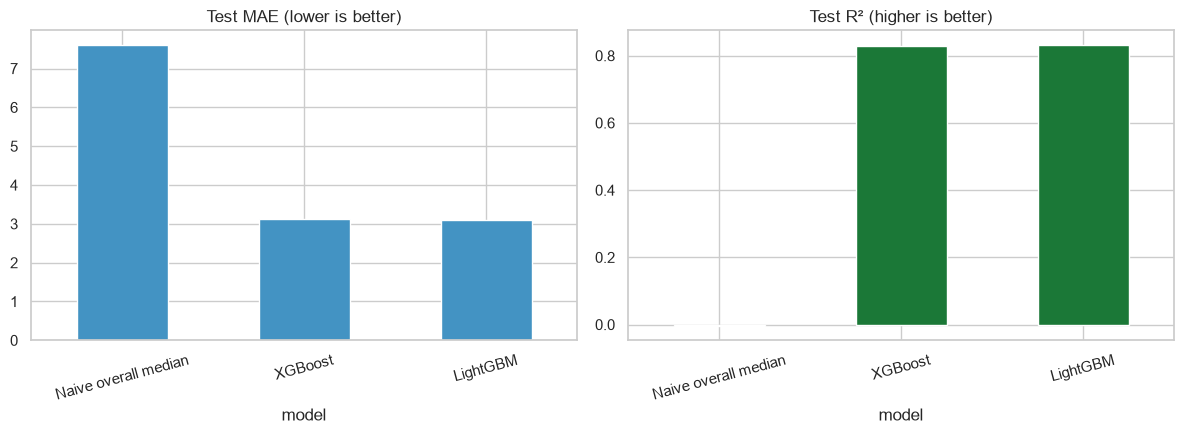

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
comparison.plot.bar(x='model', y='mae_min', ax=axes[0], color='#4393c3', legend=False)
axes[0].set_title('Test MAE (lower is better)')
axes[0].tick_params(axis='x', rotation=15)
comparison.plot.bar(x='model', y='r2', ax=axes[1], color='#1b7837', legend=False)
axes[1].set_title('Test R² (higher is better)')
axes[1].tick_params(axis='x', rotation=15)
fig.tight_layout()
fig.savefig(IMAGE_DIR / 'model_comparison.png', dpi=120, bbox_inches='tight')
plt.show()
plt.close(fig)

## 6. Prediction diagnostics and SLA errors

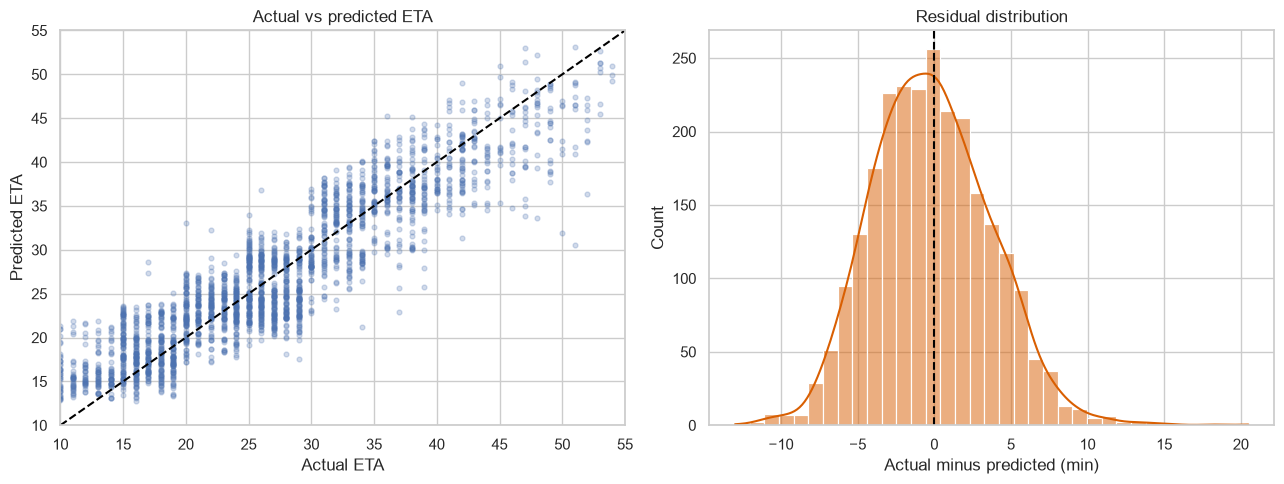

In [9]:
sample = test_predictions.sample(n=min(2500, len(test_predictions)), random_state=42)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].scatter(sample['delivery_time_min'], sample['predicted_eta_min'], alpha=0.25, s=12)
limits = [10, 55]
axes[0].plot(limits, limits, '--', color='black')
axes[0].set(xlim=limits, ylim=limits, xlabel='Actual ETA', ylabel='Predicted ETA', title='Actual vs predicted ETA')
residuals = sample['delivery_time_min'] - sample['predicted_eta_min']
sns.histplot(residuals, bins=35, kde=True, ax=axes[1], color='#d95f02')
axes[1].axvline(0, color='black', linestyle='--')
axes[1].set(title='Residual distribution', xlabel='Actual minus predicted (min)')
fig.tight_layout()
fig.savefig(IMAGE_DIR / 'prediction_diagnostics.png', dpi=120, bbox_inches='tight')
plt.show()
plt.close(fig)

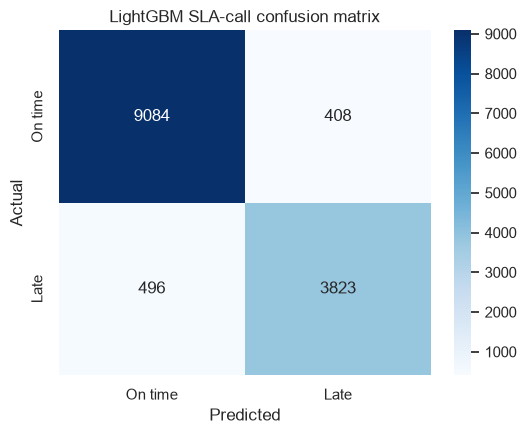

In [10]:
cm = confusion_matrix(test_predictions['actual_sla_miss'], test_predictions['predicted_sla_miss'])
fig, ax = plt.subplots(figsize=(5.5, 4.5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['On time', 'Late'], yticklabels=['On time', 'Late'], ax=ax)
ax.set(title='LightGBM SLA-call confusion matrix', xlabel='Predicted', ylabel='Actual')
fig.tight_layout()
fig.savefig(IMAGE_DIR / 'sla_confusion.png', dpi=120, bbox_inches='tight')
plt.show()
plt.close(fig)

## 7. SHAP drivers and hour-band risk

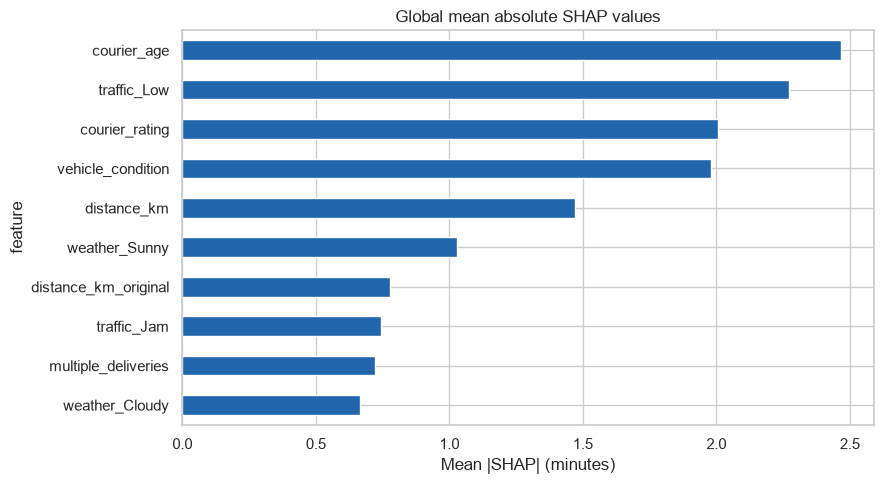

In [11]:
summary = build_summary(metrics, test_predictions)
(ROOT / 'models' / 'shap_summary.json').write_text(json.dumps(summary, indent=2), encoding='utf-8')
drivers = pd.DataFrame(summary['top_shap_drivers']).sort_values('mean_abs_shap_min')
fig, ax = plt.subplots(figsize=(9, 5))
drivers.plot.barh(x='feature', y='mean_abs_shap_min', ax=ax, color='#2166ac', legend=False)
ax.set(title='Global mean absolute SHAP values', xlabel='Mean |SHAP| (minutes)')
fig.tight_layout()
fig.savefig(IMAGE_DIR / 'shap_drivers.png', dpi=120, bbox_inches='tight')
plt.show()
plt.close(fig)

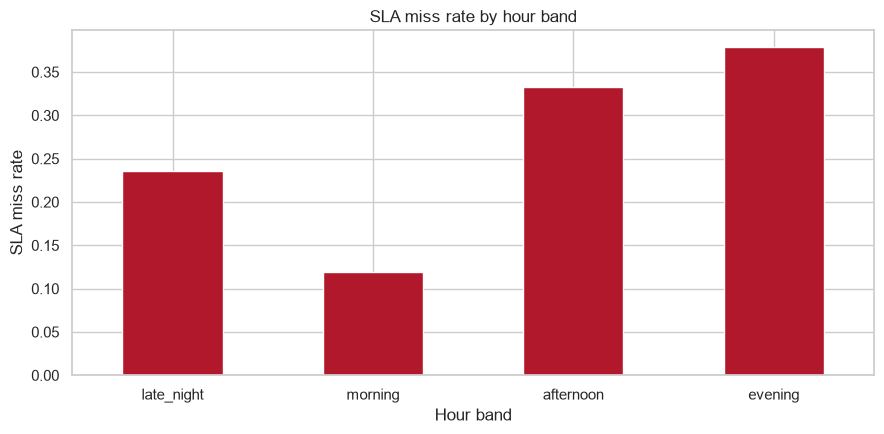

,hour_band,orders,avg_actual_eta,mae_min,sla_miss_rate
0,late_night,51,25.41,3.82,0.2353
1,morning,337,22.01,2.58,0.1187
2,afternoon,364,26.81,3.24,0.3324
3,evening,1248,28.08,3.12,0.3790


In [12]:
hour_bands = pd.DataFrame(summary['hour_band_summary'])
fig, ax = plt.subplots(figsize=(9, 4.5))
hour_bands.plot.bar(x='hour_band', y='sla_miss_rate', ax=ax, color='#b2182b', legend=False)
ax.set(title='SLA miss rate by hour band', xlabel='Hour band', ylabel='SLA miss rate')
ax.tick_params(axis='x', rotation=0)
fig.tight_layout()
fig.savefig(IMAGE_DIR / 'hour_band_risk.png', dpi=120, bbox_inches='tight')
plt.show()
plt.close(fig)
display(hour_bands[['hour_band', 'orders', 'avg_actual_eta', 'mae_min', 'sla_miss_rate']])

## 8. Findings and limits

In [13]:
winner_metrics = metrics[metrics['winner']]
worst_zone = max(summary['zone_summary'], key=lambda item: item['sla_miss_rate'])
display(Markdown(
    f"- **Model:** {metrics['winner'].title()} achieves **{winner_metrics['mae_min']:.2f} min MAE**, "
    f"**{winner_metrics['r2']:.3f} R²**, and **{winner_metrics['sla_accuracy'] * 100:.1f}% SLA-call accuracy**.\n"
    f"- **Operational risk:** {worst_zone['zone']} has the highest zone miss rate at "
    f"**{worst_zone['sla_miss_rate'] * 100:.1f}%**.\n"
    f"- **Time risk:** the evening band has the highest miss rate in the SHAP sample.\n"
    '- **Limits:** source orders are from India in 2022; Saudi locations and categories are synthetic. '
    'SHAP shows model reliance, not causation. Only 44 days are available, and missing order times fall back to midnight.'
))

- **Model:** Lightgbm achieves **3.10 min MAE**, **0.833 R²**, and **93.5% SLA-call accuracy**.
- **Operational risk:** Medina has the highest zone miss rate at **32.3%**.
- **Time risk:** the evening band has the highest miss rate in the SHAP sample.
- **Limits:** source orders are from India in 2022; Saudi locations and categories are synthetic. SHAP shows model reliance, not causation. Only 44 days are available, and missing order times fall back to midnight.